# 04 · Regolith Failure Modes, Research Gaps & Synthesis

In this final synthesis notebook, we map the biological and physical failure modes reported by student teams (`alkaline_ph`, `compaction_crusting`, `hydrophobicity_water_retention`, `nutrient_deficiency`, `heavy_metals_or_salinity`, `microbial_contamination`) and construct a **Crop Guild × Amendment Category sparsity matrix** to pinpoint high-value unexplored experimental combinations for future Plant the Moon and NASA **Lunar LEAF** campaigns.

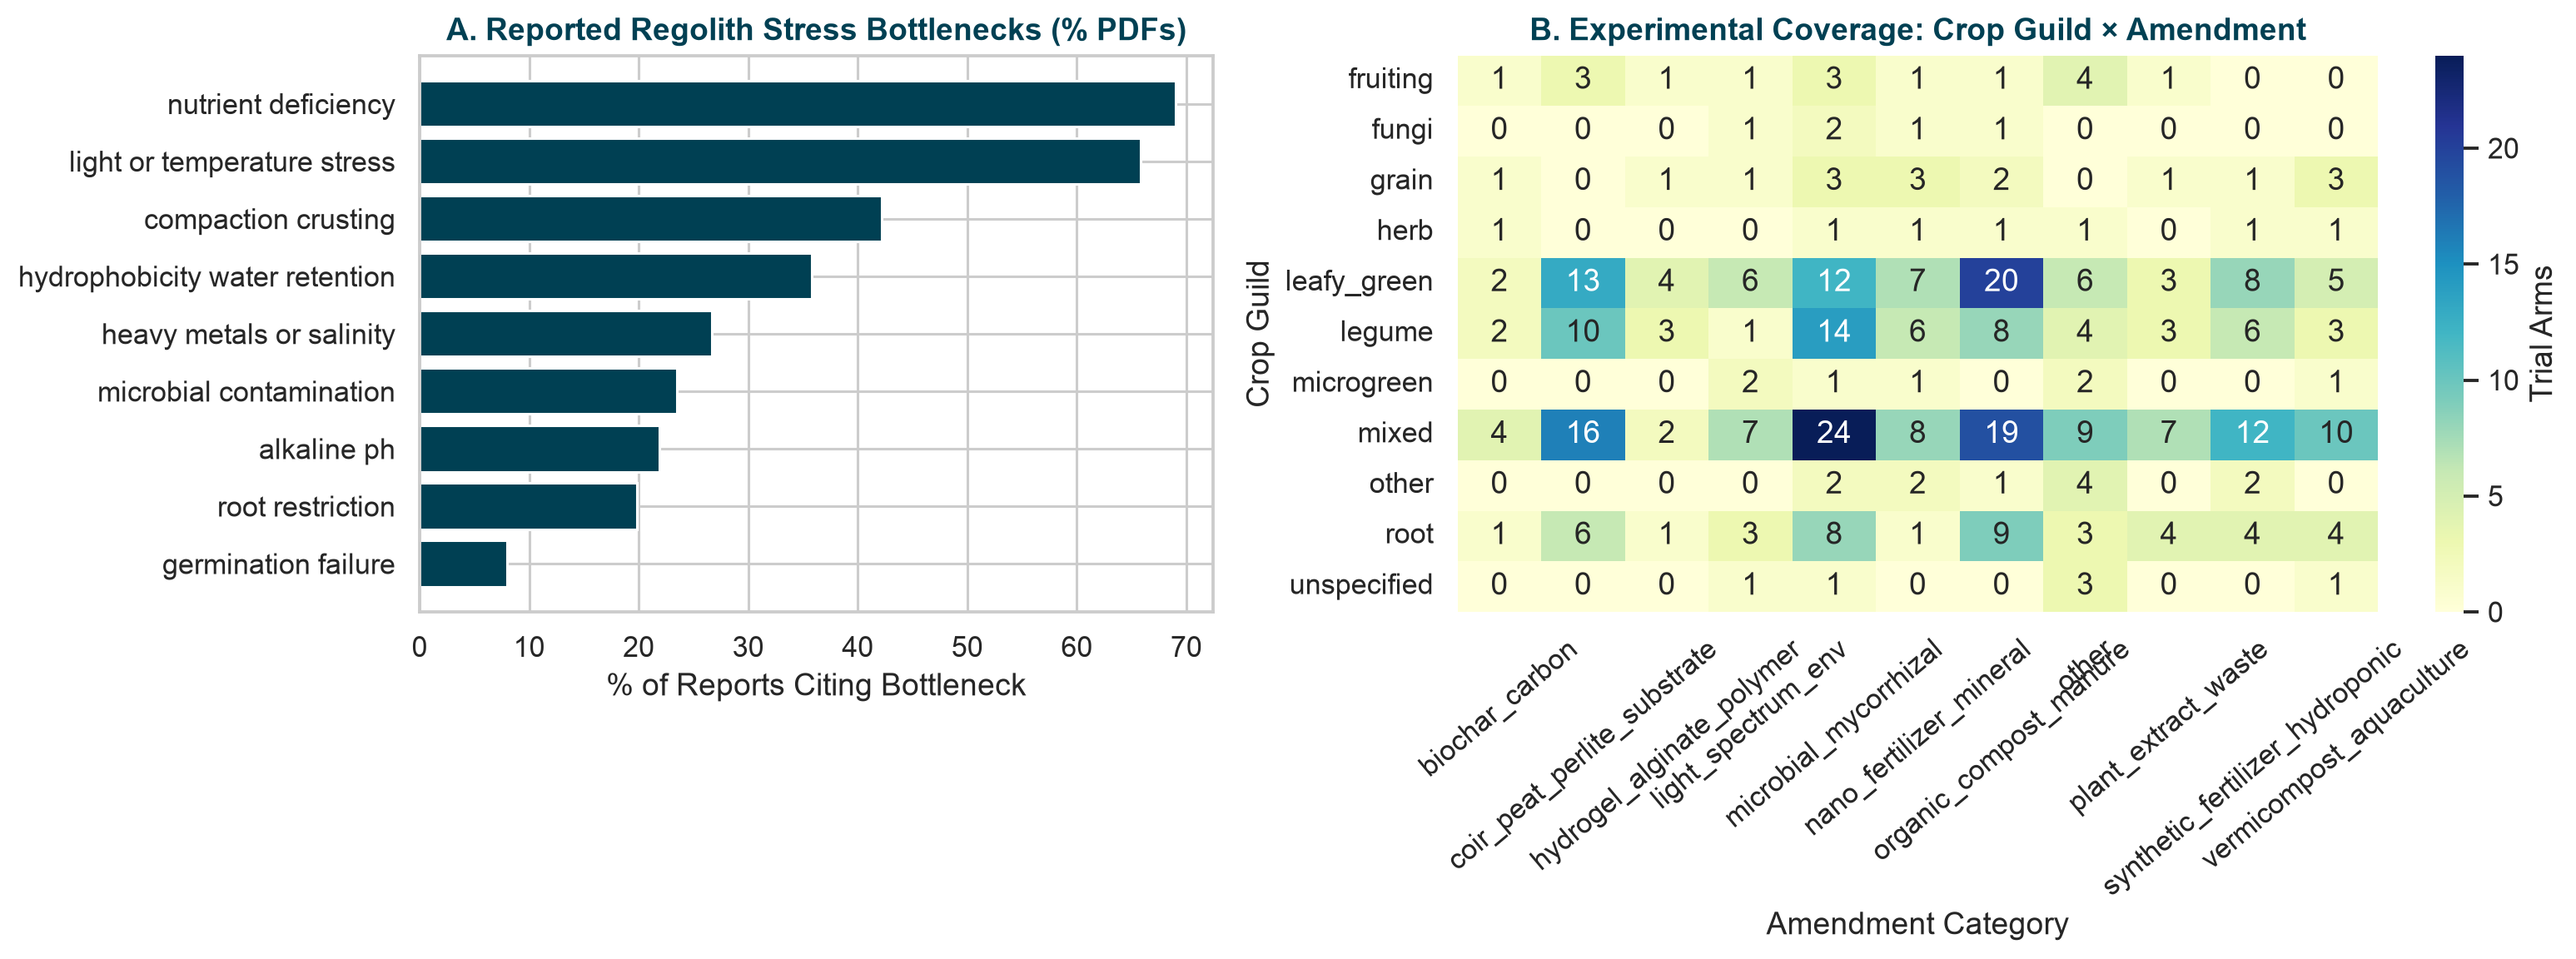

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
ROOT = Path("../..").resolve()
reports = pd.read_parquet(ROOT / "data/processed/reports.parquet")
arms = pd.read_parquet(ROOT / "data/processed/trial_arms.parquet")
pdfs = reports[reports["has_pdf"]].copy()

# Bottleneck prevalence
bn_counts = {}
for raw in pdfs["primary_bottlenecks"].dropna():
    for tag in str(raw).split(";"):
        t = tag.strip()
        if t:
            bn_counts[t] = bn_counts.get(t, 0) + 1
bn_df = pd.DataFrame(
    [{"bottleneck": k.replace("_", " "), "reports": v, "pct": round(100 * v / len(pdfs), 1)} for k, v in bn_counts.items()]
).sort_values("reports", ascending=True)

# Sparsity matrix: Crop Guild x Amendment Category
trt = arms[~arms["is_control"]].copy()
mat = pd.crosstab(trt["crop_guild"], trt["amendment_category"])

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.4), dpi=220, gridspec_kw={"width_ratios": [1, 1.45]})

axes[0].barh(bn_df["bottleneck"], bn_df["pct"], color="#004053")
axes[0].set_title("A. Reported Regolith Stress Bottlenecks (% PDFs)", fontweight="bold", color="#004053")
axes[0].set_xlabel("% of Reports Citing Bottleneck")

sns.heatmap(mat, annot=True, fmt="d", cmap="YlGnBu", cbar_kws={"label": "Trial Arms"}, ax=axes[1])
axes[1].set_title("B. Experimental Coverage: Crop Guild × Amendment", fontweight="bold", color="#004053")
axes[1].set_xlabel("Amendment Category")
axes[1].set_ylabel("Crop Guild")
axes[1].tick_params(axis="x", rotation=40)

plt.tight_layout()
fig.savefig(ROOT / "manuscript/figures/fig4.png", dpi=220, bbox_inches="tight")
plt.show()

### Identifying Under-Explored High-Potential Combinations
Cells with `0` or `1` trial arms in the `Crop Guild × Amendment` matrix highlight clear experimental whitespace—for example, combining **biochar/carbon** or **nano-fertilizer minerals** with **fruiting crops**, **grains**, or **fungal mycelium (`Pleurotus`)**, as well as pairing **hydrogel/alginate encapsulation** with **legumes** to overcome early-stage regolith crusting and hydrophobicity.

### Overall Meta-Analysis Conclusions
1. **Archive-Wide Synthesis**: Across `187` PDFs (`Spring 2021`–`Spring 2026`), overcoming regolith sterility requires simultaneous mitigation of **nutrient deficiency**, **water-retention/hydrophobicity**, and **alkaline pH / compaction**.
2. **Protocol Recommendations for Future Cohorts**: Always include paired **100% unamended regolith negative controls** alongside terrestrial positive controls, report replicate-level means + dispersion, and test underrepresented combinations identified in the sparsity matrix.
3. **FAIR Reusability**: Every figure, dataset (`reports`, `trial_arms`, `ontology_mappings`), and Typst manuscript table in this repository traces deterministically back to SHA-256-verified source PDFs and page-cited provenance quotes.